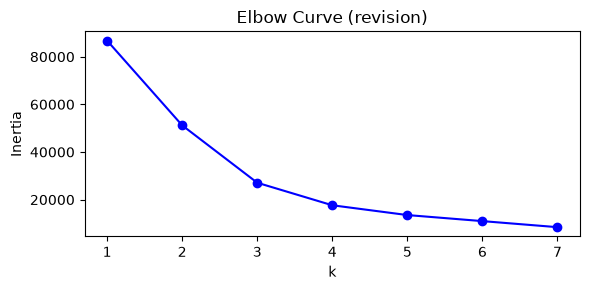

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# --- Quick revision snippet ---
np.random.seed(42)
X_rev = np.random.rand(50, 2) * 100

inertias = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_rev)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 3))
plt.plot(range(1, 8), inertias, 'bo-')
plt.title("Elbow Curve (revision)")
plt.xlabel("k"); plt.ylabel("Inertia")
plt.tight_layout(); plt.show()

# Viva notes:
# - Inertia = within-cluster sum of squared errors (WCSS); lower is better
# - Elbow = optimal k where adding more k gives diminishing returns in inertia
# - Silhouette score measures cluster cohesion and separation (-1 to +1, higher=better)
# - KMeans assumes spherical clusters; sensitive to initialisation and outliers
# - n_init=10 runs KMeans 10 times and picks the best inertia result


### Q12
Write a Python script that implements the Elbow Method to determine the optimal number of clusters for a generated dataset. (Generate dataset of your choice with 14 points)


In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


In [26]:
# Generate exactly 14 random 2D points
np.random.seed(42)
X = np.random.rand(14, 2) * 100
print("Dataset shape:", X.shape)
print("Points:\n", X)


Dataset shape: (14, 2)
Points:
 [[37.45401188 95.07143064]
 [73.19939418 59.86584842]
 [15.60186404 15.59945203]
 [ 5.80836122 86.61761458]
 [60.11150117 70.80725778]
 [ 2.05844943 96.99098522]
 [83.24426408 21.23391107]
 [18.18249672 18.34045099]
 [30.4242243  52.47564316]
 [43.19450186 29.12291402]
 [61.18528947 13.94938607]
 [29.21446485 36.63618433]
 [45.60699842 78.51759614]
 [19.96737822 51.42344384]]


In [27]:
# Compute inertia for k = 1 to 10
inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertias.append(model.inertia_)

print("k  -> Inertia")
for k, inr in zip(k_values, inertias):
    print(f"k={k} -> {inr:.2f}")


k  -> Inertia
k=1 -> 19885.36
k=2 -> 10638.02
k=3 -> 6186.11
k=4 -> 3434.12
k=5 -> 2316.67
k=6 -> 1525.93
k=7 -> 834.68
k=8 -> 564.85
k=9 -> 384.01
k=10 -> 249.09


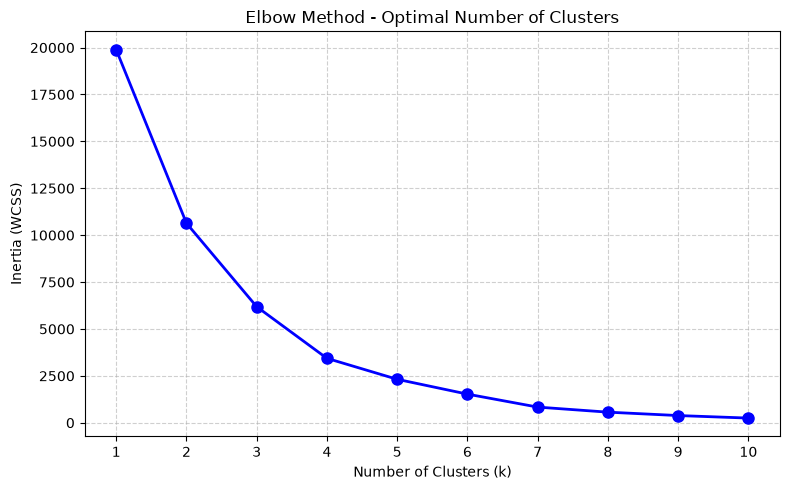

In [28]:
# Plot elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, 'bo-', linewidth=2, markersize=8)
plt.title("Elbow Method - Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(list(k_values))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Q13
Use make_blobs to generate 300 samples. Analyse the data and apply KMeans clustering and generate the graph for better representation. Show what happens if you change n_clusters count from 2 to 7 (2, 3, 4, 5, 6, 7)?


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs


In [30]:
# Generate 300 samples with 4 natural centers
X, y_true = make_blobs(n_samples=300, centers=4, random_state=42)
print("Dataset shape:", X.shape)


Dataset shape: (300, 2)


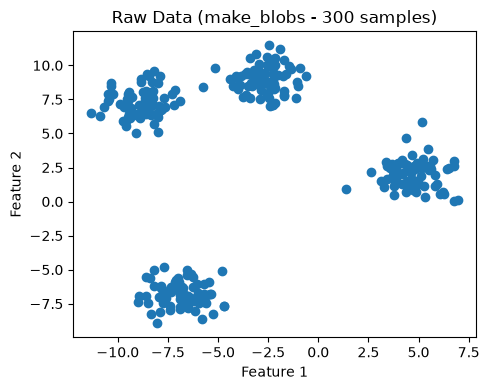

In [31]:
# Plot raw data (no cluster labels yet)
plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1])
plt.title("Raw Data (make_blobs - 300 samples)")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()


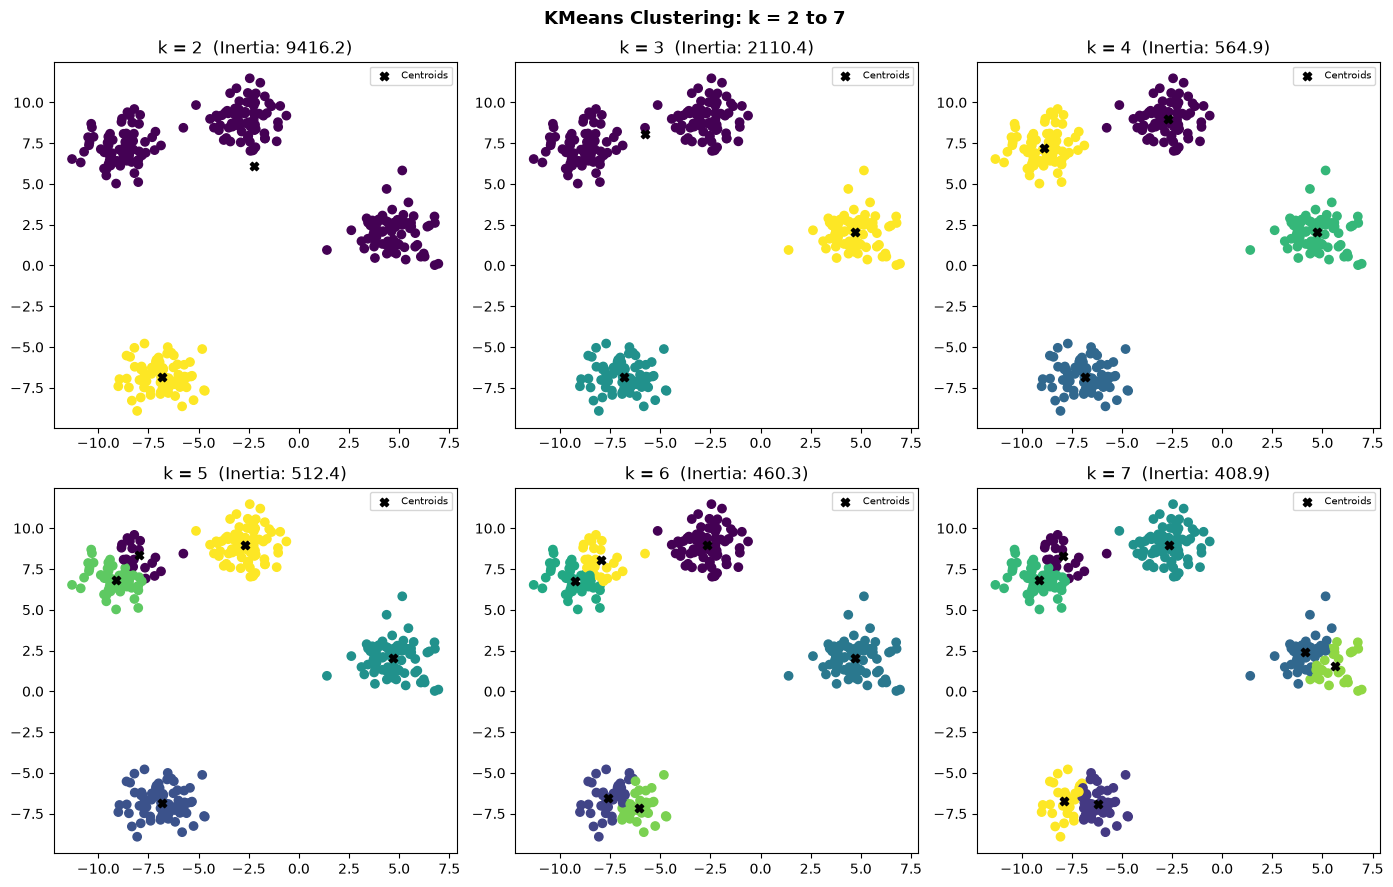

In [32]:
# Subplot grid 2x3 for k = 2, 3, 4, 5, 6, 7
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
k_values = [2, 3, 4, 5, 6, 7]

for ax, k in zip(axes.flatten(), k_values):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    centroids = model.cluster_centers_

    # Scatter colored by cluster
    ax.scatter(X[:, 0], X[:, 1], c=labels)
    # Mark centroids with X
    ax.scatter(centroids[:, 0], centroids[:, 1],
               c='black', marker='X', label='Centroids')
    ax.set_title(f"k = {k}  (Inertia: {model.inertia_:.1f})")
    ax.legend(loc='upper right', fontsize=7)

plt.suptitle("KMeans Clustering: k = 2 to 7", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [33]:
# Conclusion:
# At k=4, clusters best match natural groupings (inertia drops sharply before this).
# Increasing k beyond optimal splits natural groups into arbitrary sub-clusters.
# Inertia always decreases with k, so use elbow/silhouette to pick optimal k.


### Q14
Generate random dataset with 35 points. Apply KMeans clustering and generate the plot with each cluster points with different colours. What is the impact of varying cluster count? Justify your understanding with suitable graphs.


In [34]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


In [35]:
# Generate exactly 35 random 2D points
np.random.seed(42)
X = np.random.rand(35, 2) * 100
print("Dataset shape:", X.shape)


Dataset shape: (35, 2)


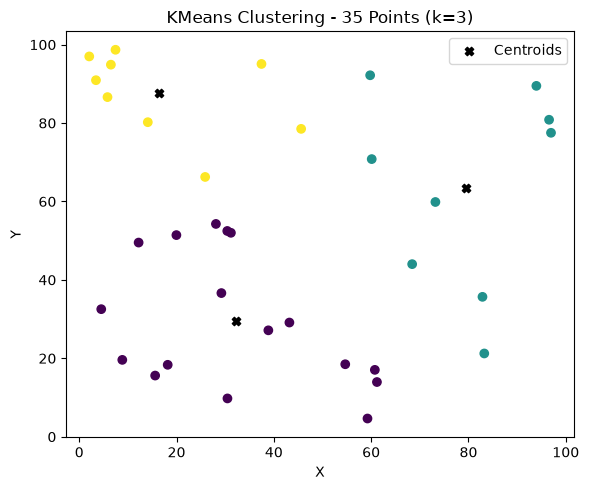

Inertia for k=3: 19697.88


In [36]:
# Apply KMeans with k=3 (default first look)
model = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = model.fit_predict(X)
centroids = model.cluster_centers_

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.scatter(centroids[:, 0], centroids[:, 1],
            c='black', marker='X', label='Centroids')
plt.title("KMeans Clustering - 35 Points (k=3)")
plt.xlabel("X"); plt.ylabel("Y")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Inertia for k=3: {model.inertia_:.2f}")


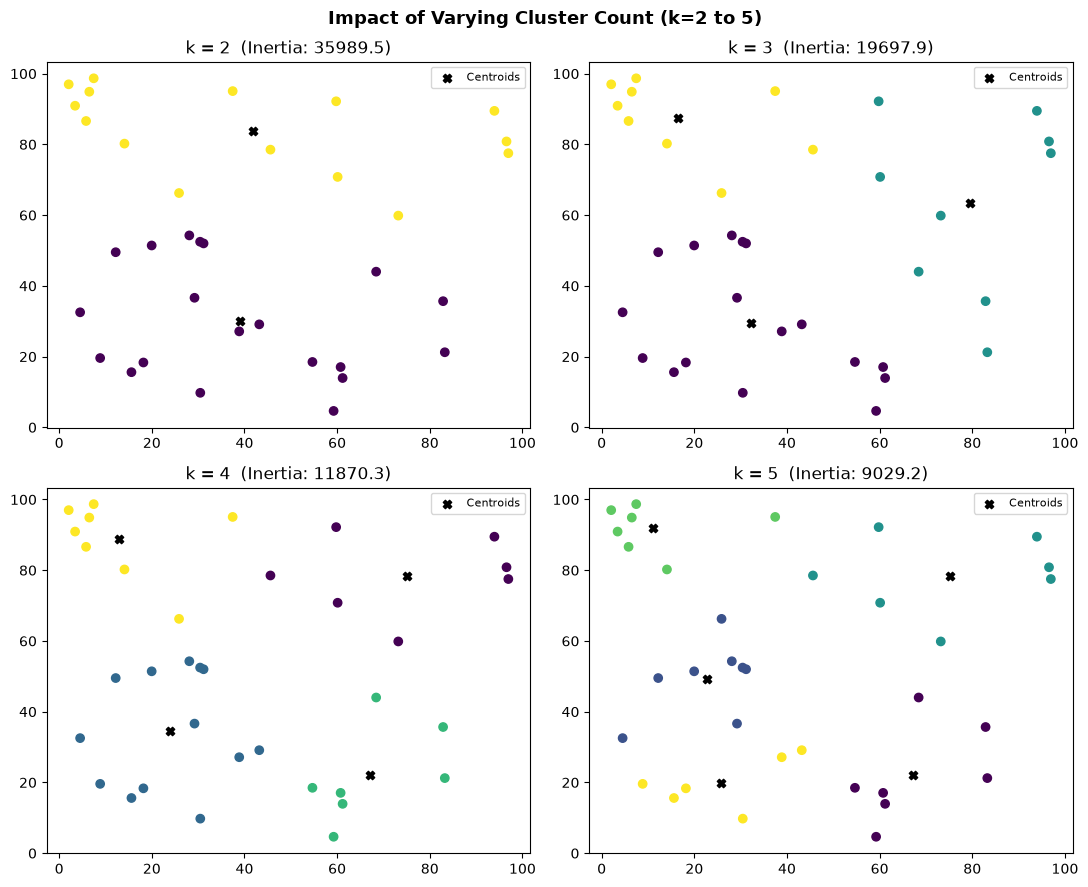

In [37]:
# Subplot grid for k = 2, 3, 4, 5 - impact of varying cluster count
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
k_values = [2, 3, 4, 5]

for ax, k in zip(axes.flatten(), k_values):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    centroids = model.cluster_centers_

    ax.scatter(X[:, 0], X[:, 1], c=labels)
    ax.scatter(centroids[:, 0], centroids[:, 1],
               c='black', marker='X', label='Centroids')
    ax.set_title(f"k = {k}  (Inertia: {model.inertia_:.1f})")
    ax.legend(fontsize=8)

plt.suptitle("Impact of Varying Cluster Count (k=2 to 5)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


In [39]:
# Conclusion:
# At k=3, clusters best match natural groupings (inertia drops sharply before this).
# Increasing k beyond optimal splits natural groups into arbitrary sub-clusters.
# Inertia always decreases with k, so use elbow/silhouette to pick optimal k.